РГР по дисциплине **вероятность и статистика**

Новиков Павел J3210 ISU: 505000

### *Квантильное преобразование*
Пусть $\mathcal{X} \sim F_x(x)$, рассмотрим $Y = F_x(\mathcal{X})$ :

$P(Y \le y) = P(F_x(\mathcal{X}) \le y) = P(\mathcal{X} \le F_x^{-1}(y)) = F_x(F_x^{-1}(y)) = y$

=> $F_y(y) = \begin{cases} y, & x \in [0, 1] \\ 0, &  y < 0 \\ 1, & y > 1\end{cases}$ нормальное распредедение

Если функция кусочно постоянна на каком либо промежутке, то берем минимальное значение, функция распределения от которого больше y, то есть если функция посмтоянна на [a, b), $F_x(b - 0) = k, k \in (0, 1)$ и $F_x(b) = k + m$ то для любого y $\in (k + m)$ значение будет b, в случаи,если функция постоянна на [a, b] и $F_x(a) = F_x(b)$, то для y, который попал в эту вероятность возьмем наименьшее значение a

Тогда для генерации точек буду использовать генерацию точек для нормлаьного распределения, после чего переводить их в исходное с помощью обратной функции распределения.


#### Вариант 13
$$F_x(x) = 
\begin{cases}  
0, & x < -1 \\
0.07, & -1 \le x < 0\\
0.65 * \frac{1 - e^{-x}}{1 + e^{-x}} + 0.245, & 0 \le x < 4\\
0.65 * \frac{1 - e^{-x}}{1 + e^{-x}} + 0.35, & x \geq 4
\end{cases}
$$

$$
F_x(x) = \lambda * F_1(x) + (1 - \lambda) * F_2(x),  \lambda  \in [0, 1]
$$
$$
\lambda = 0.07 + 0.35 - 0.245 + 0.245 - 0.07= 0.35
$$
$$
F_1(x) = 
\begin{cases} 
0, & x < -1 \\
\frac{0.07}{0.35}, & -1 \le x < 0\\
\frac{0.245}{0.35}, & 0 \le x < 4\\

1, & x \geq 4
\end{cases}
$$

$$
F_2(x) =
\begin{cases}
0, & x < 0 \\
\frac{0.65}{0.65} * \frac{1 - e^{-x}}{1 + e^{-x}}, & x \geq 0

\end{cases}
$$
$$
EX_1 = - 1 * 0.2 + 4 * 0.3 = -0.2 + 1.2 = 1
$$

$$
EX_1^{2} = 1 * 0.2 + 16 * 0.3 = 0.2 + 4.8 = 5
$$

$$
f_X(x) = F_2(x) ' = \begin{cases}
0, & x < 0\\
2 * \frac{e^{-x}}{(1 + e^{-x})^{2}}, & x \geq 0

\end{cases}
$$

$$
EX_2 = \int_{0}^{+\infty} 2 * \frac{e^{-x}}{(1 + e^{-x})^{2}} * x * dx = 2 * \ln{2}
$$
$$
EX_2^{2} = \int_{0}^{+\infty} 2 * \frac{e^{-x}}{(1 + e^{-x})^{2}} * x^{2} * dx = 2 * \frac{\pi^{2}}{6} = \frac{\pi^2}{3}
$$
$$
EX = \lambda * EX_1 + (1 - \lambda) * EX_2 = 0.35 * 1 + 0.65 * 2 * \ln{2} \approx 1.25103
$$
$$
DX =
0.35 * 5 + 0.65 * \frac{\pi^{2}}{3} - (1 * 0.35 + 0.65 * 2 * \ln{2})^{2} \approx 2.32150
$$

### Реализация квантильного преобразования

In [126]:
import math
def g_1(y: float, a: float) -> float:
    return math.log((0.65 + y - a) / (0.65 - (y - a)), math.exp(1))

def F_converted(x: float) -> float | None:
    if x == 0:
        return -1
    if x == 1:
        return 0
    if x <= 0.07:
        return -1
    if x <= 0.245:
        return 0
    if x < 0.65 * (1 - math.exp(-4)) / (1 + math.exp(-4)) + 0.245:
        return g_1(x, 0.245)
    if x < 0.65 * (1 - math.exp(-4)) / (1 + math.exp(-4)) + 0.35:
        return 4
    return g_1(x, 0.35)
    
    

In [127]:
import random
x = [random.random() for _ in range(100_000)]
y = [F_converted(t) for t in x]

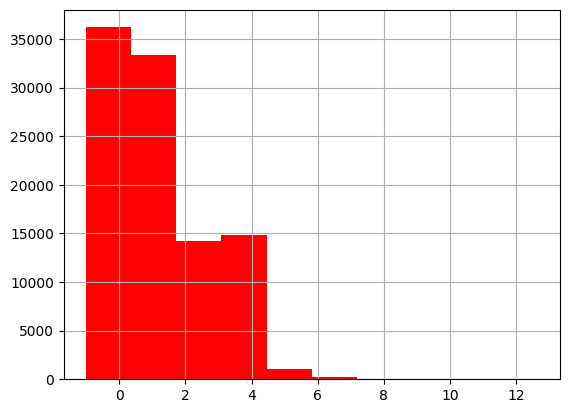

In [128]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
ax.hist(y, color="red")
ax.grid()
plt.show()

In [129]:
ex_teor = 1.25103
dx_teor = 2.32150
ex = sum(y) / len(y)
dx = sum([(t - ex)** 2 for t in y]) / len(y)
error = (abs(ex_teor - ex), abs(dx_teor - dx))
error

(0.0071196437120508715, 0.004143662027338735)

0.9999999999984646


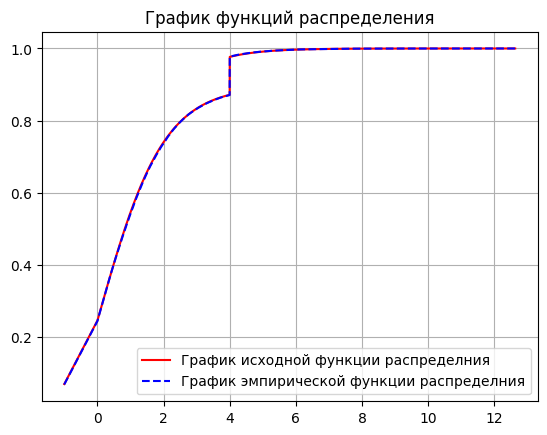

In [130]:
def F_x(x):
    if x < -1:
        return 0
    if x < 0:
        return 0.07
    if x < 4:
        return 0.65 * (1 - math.exp(-x)) / (1 + math.exp(-x)) + 0.245

    return 0.65 * (1 - math.exp(-x)) / (1 + math.exp(-x)) + 0.35
Y_1 = [F_x(t) for t in sorted(set(y))]
Y_2 = []
y = sorted(y)
k = 1
n = len(y)
for i in range(0, len(y) - 1):
    if y[i] == y[i+1]:
        k += 1
    else:
        if len(Y_2) == 0:
            Y_2.append(k / n)
        else:
            Y_2.append(Y_2[-1] + k / n)
        k = 1
    if i == len(y) - 2:
        Y_2.append(Y_2[-1] + k / n)
x = sorted(set(y))
fig, ax = plt.subplots()
ax.grid()
ax.plot(x, Y_1, color="red", label="График исходной функции распределния")
ax.plot(x, Y_2, color="blue", ls="--", label="График эмпирической функции распределния")
plt.title("График функций распределения")
ax.legend()
print(Y_2[-1])

#### Задание 2  Вариант 13

X - дискретная случ велечина
P(X = 0) = $\frac{1}{5}, P(X = 2) = \frac{2}{5}, P(X = 7) = \frac{2}{5}$

Y - непрерывная с плотностью: 

$
f_y(y) = \frac{3y^{2}}{2}, y \in [-1, 1]
$

X и Y независимы

Рассмотрим Z = X + Y

$
F_z(t) = P(Z \le t) = P(Y \le t - X) = \sum_{i=1}^{n}P(Y \le t - x_i | X = x_i) = P(Y \le t - x_i) * P(X = x_i) = \sum_{i=1}^{n}F_y(t - x_i) * P(X = x_i)
$

$
F_z(t) = \frac{1}{5} * F_y(t) + \frac{2}{5} * F_y(t-2) + \frac{2}{5} * F_y(t-7)
$

$
F_z(t) = 
\begin{cases}
0, & t < -1\\
\frac{t^{3} + 1}{10}, & t \in[-1;1)\\
\frac{1}{5} + \frac{(t - 2)^{3} + 1}{5}, & t \in[1, 3)\\
\frac{3}{5}, & t \in [3, 6)\\
\frac{3}{5} + \frac{(t - 7)^{3} + 1}{5}, & t \in [6, 8]\\
1, & t > 8
\end{cases}
$

$
f_z(t) = 
\begin{cases}
\frac{3t^{2}}{10}, & t \in [-1, 1)\\
\frac{3(t-2)^{2}}{5}, & t \in [1, 3]\\
\frac{3(t-7)^{2}}{5}, & t \in [6, 8]\\
0, & иначе
\end{cases}
$

$
EZ = \int_{-1}^{1}\frac{3t^{2}}{10} * t * dt + \int_{1}^{3}\frac{3(t-2)^{2}}{5} * t * dt + \int_{6}^{8}\frac{3(t-7)^{2}}{5} * t * dt = \frac{3}{10}\int_{-1}^{1}t^3dt + \frac{3}{5}\int_{1}^{3}(t^3-4t^2+4t)dt + \frac{3}{5}\int_{6}^{8}(t^3-14t^2+49t)dt
= \frac{3}{10} * \left[\frac{t^4}{4}\right]_{-1}^{1} + \frac{3}{5} * \left[\frac{t^4}{4}-\frac{4t^3}{3}+2t^2\right]_{1}^{3} + \frac{3}{5} * \left[\frac{t^4}{4}-\frac{14t^3}{3}+\frac{49t^2}{2}\right]_{6}^{8}
= 0 + \frac{4}{5} + \frac{14}{5}
= \frac{18}{5} = 3.6
$

$EZ = EX + EY = \frac{2}{5} * 2 + \frac{2}{5} * 7 + 0 = \frac{18}{5} = 3.6$  EY = 0 ввиду симметрии плотности на [-1, 1]

$DZ = EZ^{2} - (EZ)^{2}$

$
EZ^{2} = \int_{-1}^{1}\frac{3t^{2}}{10} * t^{2} * dt + \int_{1}^{3}\frac{3(t-2)^{2}}{5} * t^{2} * dt + \int_{6}^{8}\frac{3(t-7)^{2}}{5} * t^{2} * dt =\int_{-1}^{1}\frac{3}{10}t^{4}\,dt+\int_{1}^{3}\frac{3}{5}(t-2)^{2}t^{2}\,dt+\int_{6}^{8}\frac{3}{5}(t-7)^{2}t^{2}\,dt
=\frac{3}{10}\cdot\frac{2}{5}+\frac{3}{5}\int_{1}^{3}(t^{4}-4t^{3}+4t^{2})\,dt+\frac{3}{5}\int_{6}^{8}(t^{4}-14t^{3}+49t^{2})\,dt
=\frac{3}{25}+\frac{3}{5}\Bigl[\frac{t^{5}}{5}-t^{4}+\frac{4t^{3}}{3}\Bigr]_{1}^{3}+\frac{3}{5}\Bigl[\frac{t^{5}}{5}-\frac{14t^{4}}{4}+\frac{49t^{3}}{3}\Bigr]_{6}^{8}
=\frac{3}{25}+\frac{3}{5}\Bigl(\frac{46}{15}\Bigr)+\frac{3}{5}\Bigl(\frac{496}{15}\Bigr)
=\frac{3}{25}+\frac{46}{25}+\frac{496}{25}=\frac{545}{25}=\frac{109}{5}
$

$
DZ = \frac{109}{5} - \frac{324}{25} = \frac{545 - 324}{25} = \frac{221}{25}
$

$
DZ = Cov(Z, Z) = Cov(X, X) + Cov(Y, Y) + 2Cov(X, Y) = Cov(X, X) + Cov(Y, Y) = DX + DY
$

$
DX = (0 - \frac{18}{5})^2 * \frac{1}{5} + (2 - \frac{18}{5})^2 * \frac{2}{5} + (7 - \frac{18}{5})^2 * \frac{2}{5} = \frac{206}{25}
$

$
DY = E(Y - EY)^{2} = EY^2 = \int_{-1}^{1} \frac{3y^2}{2} * y^{2} dy = \frac{3}{5}
$

$
DZ = \frac{15}{25} + \frac{206}{25} = \frac{221}{25}
$

In [131]:
ez_teor_2 = 3.6
de_teor_2 = 221/25
def sign(t):
    if t > 0:
        return 1
    if t < 0:
        return -1
    return 0

def F_2_converted(y):  ##Использовался модуль, а потом домножение на знак, так как дробные степени отрицательных чисел считает не точно(возвращает комплексное число)
    if y == 0:
        return -1
    if y < 0.2:
        return (abs(10 * y - 1)) ** (1/3) * sign(10 * y - 1)
    if y < 0.6:
        return ((abs(5 * y - 2)) ** (1/3) * sign(5 * y - 2) + 2) 
    if y == 0.6:
        return 3
    if y <= 1:
        return ((abs(5 * y - 4)) ** (1/3) * sign(5 * y - 4) + 7) 
x = [random.random() for _ in range(1_000_000)]
y = [F_2_converted(xi) for xi in x]
ez_2 = sum(y) / len(y)
dz = sum([(t - ez_2)** 2 for t in y]) / len(y)
error_2 = (abs(ez_teor_2 - ez_2), abs(de_teor_2 - dz))
error_2
    

(0.00379081938298631, 0.005184969346506918)

Задание 3

Обратное преобразование:

$X_1=\dfrac{\operatorname{atan2}(Y_2,Y_1)}{2\pi}\bmod 1$

$X_2=e^{-\frac{(Y_1^2+Y_2^2)}{2}}$

$
J = \begin{pmatrix}
\frac{dY1}{dX1} & \frac{dY1}{dX2}\\
\frac{dY2}{dX1} & \frac{dY2}{dX2}
\end{pmatrix} = 
\begin{pmatrix}
-sin(2\pi X_1) * 2 \pi * \sqrt{-2 \ln{X_2}} & 
\frac{1}{\sqrt{-2 \ln{x}}} * (-\frac{1}{X_2}) * cos(2 \pi X_1)\\
2 \pi * \sqrt{-2 \ln{X_2}} * cos(2 \pi X_1) & \frac{1}{\sqrt{-2 \ln{x}}} * (-\frac{1}{X_2}) * sin(2\pi X_1)
\end{pmatrix}
$

$
Det(J) = \frac{2 \pi}{X_2} => \frac{1}{Det(J)} = \frac{X_2}{2 \pi}
$

$
P_2(Y_1, Y_2) = P_1(X_1, X_2) * \frac{1}{Det(J)} = P_1(\dfrac{\operatorname{atan2}(Y_2,Y_1)}{2\pi}\bmod 1, e^{-\frac{Y_1^2+Y_2^2}{2}}) * \frac{X_2}{2 \pi}
$

так как оба аргумента функции лежат с вероятностью 1 в (0, 1), то плотность от этих аргументов равна 1 => $P_2(y1, y2) = \frac{X_2}{2 \pi} = \frac{e^{-\frac{Y_1^2+Y_2^2}{2}}}{2 \pi} $ 

Где $P_1$ - совместная функция пдотности x1 и x2, $P_2$ - совместная функция плотности y1, y2

Так как $P_2(y1, y2) = \frac{X_2}{2 \pi} = \frac{e^{-\frac{Y_1^2+Y_2^2}{2}}}{2 \pi}$, а это есть не что иное, как стандартная плотность совместного нормального распределения, то можно сделать вывод, что сами велечины независимы и так же имеют стандартное нормальное распределение



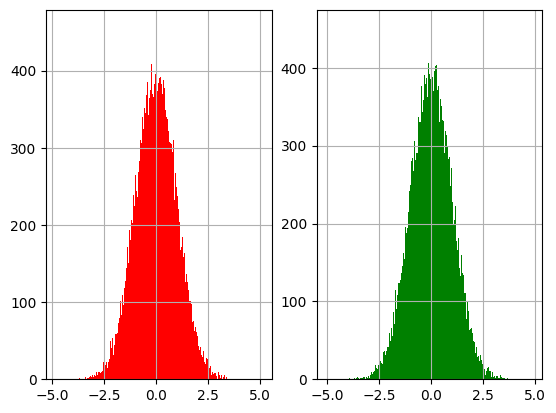

In [132]:
X_1 = [random.random() for _ in range(1_000_000)]
X_2 = [random.random() for _ in range(1_000_000)]
def Y1(x1, x2):
    return math.sqrt(-2 * math.log(x1, math.exp(1))) * math.cos(2 * math.pi * x2)

def Y2(x1, x2):
    return math.sqrt(-2 * math.log(x1, math.exp(1))) * math.sin(2 * math.pi * x2)

fig, ax = plt.subplots(1, 2)
Y_1 = []
Y_2 = []
for i in range(len(X_1)):
    Y_1.append(Y1(X_1[i], X_2[i]))
    Y_2.append(Y2(X_1[i], X_2[i]))

ax[0].hist(Y_1, color="red", bins=10000)
ax[0].grid()
ax[1].hist(Y_2, color="green", bins=10000)
ax[1].grid()
plt.show()


In [134]:
import numpy as np
np.corrcoef(Y_1, Y_2)[0][1]

-0.0007103158612743823

In [144]:
Y_1_test = Y_1
Y_2_test = Y_2
Y_3 = []
for i in range(len(Y_1_test)):
    Y_3.append(math.exp(-((Y_1_test[i] ** 2 + Y_2_test[i] ** 2) / 2)) / (2 * math.pi))

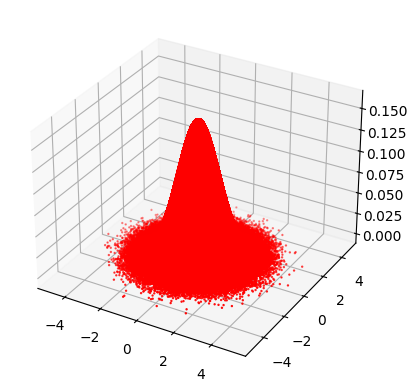

In [145]:
fig = plt.figure()
ax_3d = fig.add_subplot(projection='3d')
ax_3d.scatter(Y_1_test, Y_2_test, Y_3, c='red', s=0.5)
plt.show()

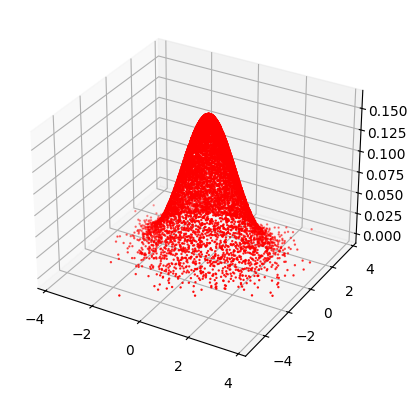

In [147]:
Y_1_test = Y_1[0:10_000]
Y_2_test = Y_2[0:10_000]
Y_3 = []
for i in range(len(Y_1_test)):
    Y_3.append(math.exp(-((Y_1_test[i] ** 2 + Y_2_test[i] ** 2) / 2)) / (2 * math.pi))
fig = plt.figure()
ax_3d = fig.add_subplot(projection='3d')
ax_3d.scatter(Y_1_test, Y_2_test, Y_3, c='red', s=0.5)
plt.show()